# Grover Operator / Amplitude Amplification — CUDA-Q Implementation

**Primitive:** 2-qubit Grover search, oracle marks |11>, one Grover iteration
`G = D * O` applied after the uniform-superposition state prep. With N = 4
basis states and M = 1 marked state, one iteration is exact: it drives the
success probability on |11> to 1.0 with zero shot noise in the ideal case.

**SETUP (must match the Qiskit notebook exactly for results to line up)**
- N QUBITS: 2
- GATES (shared source of truth, used for kernel build AND diagram):
  1. H on qubit 0            -- superposition prep
  2. H on qubit 1            -- superposition prep
  3. CZ, qubits (0, 1)       -- ORACLE: phase-flips |11> only
  4. H on qubit 0            -- diffusion, part 1
  5. H on qubit 1            -- diffusion, part 1
  6. X on qubit 0            -- diffusion, part 2
  7. X on qubit 1            -- diffusion, part 2
  8. CZ, qubits (0, 1)       -- diffusion's inversion-about-|00> phase flip
  9. X on qubit 0            -- diffusion, part 3
  10. X on qubit 1           -- diffusion, part 3
  11. H on qubit 0           -- diffusion, part 4
  12. H on qubit 1           -- diffusion, part 4
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE: normalized so first nonzero amplitude (ascending bitstring order) is real and positive

**Theory recap:** Steps 1-2 build the uniform superposition
`|s> = (|00>+|01>+|10>+|11>)/2`. The oracle `O` (step 3) is a single CZ,
since flipping the phase of only `|11>` is exactly what a controlled-Z does
on a 2-qubit register -- no ancilla needed. The diffusion operator
`D = H(x)H . (2|00><00| - I) . H(x)H` is realized by steps 4-11:
sandwich an "inversion about |00>" (X, X, CZ, X, X -- which phase-flips
only `|00>`) between two layers of H. For N = 4, M = 1, the optimal number
of iterations is `round(pi/4 * sqrt(N/M)) = 1`, and this is one of the rare
cases where the amplification is exact: `sin^2(3*theta) = 1` for
`theta = arcsin(sqrt(1/4)) = pi/6`, so a single iteration should leave the
register in `|11>` with probability 1.0, no other outcomes possible even
before taking any shots.

**Important ordering warning:** CUDA-Q's native state-vector/sample indexing
is commonly documented as treating qubit 0 as the **most-significant**
(leftmost) bit -- opposite of Qiskit's rightmost/least-significant
convention. This notebook does NOT just assume that; Section 1 verifies it
empirically with a calibration kernel and derives `NEEDS_REVERSAL`
programmatically, and every reversal downstream is driven by that measured
flag rather than a hardcoded `[::-1]`.

**IMPORTANT: Run every cell in order, top to bottom** (Kernel -> Restart & Run All).

In [2]:
# Run this cell first if you get ModuleNotFoundError.
# Correct package name is "cudaq" (NOT "cuda-quantum").
# Requires pip >= 24.0, and Linux (x86_64/aarch64) or macOS (arm64/Apple Silicon). Windows needs WSL.
!pip install --upgrade pip -q
!pip install -q cudaq
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.

In [3]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import cudaq

np.random.seed(42)

N_QUBITS = 2
SHOTS = 10000
SEED = 42
cudaq.set_random_seed(SEED)

# FIX (carried over from the previous W-state notebook's root-cause fix): pin the CPU
# simulator target explicitly BEFORE any kernel is built/compiled/run. Without this,
# on a machine with no NVIDIA GPU, CUDA-Q's target auto-detection / JIT compile path for
# a GPU-capable backend can stall indefinitely instead of failing fast, which looks like
# a hang and gets killed as a KeyboardInterrupt whenever the cell is eventually interrupted.
cudaq.set_target("qpp-cpu")
assert cudaq.get_target().name == "qpp-cpu", "Target did not get set to qpp-cpu as expected!"
print(f"CUDA-Q target: {cudaq.get_target().name}")

# GATES: shared source of truth for the matplotlib diagram, and kept in
# lockstep with the explicit kernel body below (Section 2).
# Format: (gate_name, qubits_list, param).
#   "h":  qubits=[target]
#   "x":  qubits=[target]
#   "cz": qubits=[qubit_a, qubit_b]  (symmetric -- order doesn't affect the operation)
GATES = [
    ("h",  [0],    None),   # 1. superposition prep
    ("h",  [1],    None),   # 2. superposition prep
    ("cz", [0, 1], None),   # 3. ORACLE: marks |11>
    ("h",  [0],    None),   # 4. diffusion
    ("h",  [1],    None),   # 5. diffusion
    ("x",  [0],    None),   # 6. diffusion
    ("x",  [1],    None),   # 7. diffusion
    ("cz", [0, 1], None),   # 8. diffusion: inversion about |00>
    ("x",  [0],    None),   # 9. diffusion
    ("x",  [1],    None),   # 10. diffusion
    ("h",  [0],    None),   # 11. diffusion
    ("h",  [1],    None),   # 12. diffusion
]
print("Gate sequence:", GATES)
print(f"Total gates: {len(GATES)}")

CUDA-Q target: qpp-cpu
Gate sequence: [('h', [0], None), ('h', [1], None), ('cz', [0, 1], None), ('h', [0], None), ('h', [1], None), ('x', [0], None), ('x', [1], None), ('cz', [0, 1], None), ('x', [0], None), ('x', [1], None), ('h', [0], None), ('h', [1], None)]
Total gates: 12


## 1. Bit-ordering calibration (verify, don't assume)

We build a tiny kernel that applies X to the *highest-index* qubit only (qubit 1) and check which native statevector index lights up. Under the qubit-0-rightmost CONTRACT, the expected bitstring is `"10"` (leftmost char = qubit 1 = 1, the rest = 0). We compare CUDA-Q's actual raw output against that, and derive `NEEDS_REVERSAL` from the result instead of trusting documentation.

In [4]:
@cudaq.kernel
def _calibration_kernel():
    q = cudaq.qvector(2)
    x(q[1])  # flip the highest-index qubit only, leave the rest at |0>

calib_state = cudaq.get_state(_calibration_kernel)
calib_amps = np.array(calib_state)

nonzero_idx = int(np.argmax(np.abs(calib_amps)))
native_bitstring = format(nonzero_idx, f"0{N_QUBITS}b")
expected_contract_bitstring = "1" + "0" * (N_QUBITS - 1)  # highest qubit = leftmost = 1, rest 0

if native_bitstring == expected_contract_bitstring:
    NEEDS_REVERSAL = False
elif native_bitstring[::-1] == expected_contract_bitstring:
    NEEDS_REVERSAL = True
else:
    raise RuntimeError(f"Calibration inconclusive: got '{native_bitstring}', "
                        f"expected '{expected_contract_bitstring}' or its reverse.")

print(f"Native bitstring for X(qubit {N_QUBITS-1}) only: '{native_bitstring}'")
print(f"Expected under contract (qubit0=rightmost):        '{expected_contract_bitstring}'")
print(f"NEEDS_REVERSAL = {NEEDS_REVERSAL}")

Native bitstring for X(qubit 1) only: '10'
Expected under contract (qubit0=rightmost):        '10'
NEEDS_REVERSAL = False


## 2. Build the kernel explicitly (kept in lockstep with GATES above)

In [5]:
@cudaq.kernel
def grover_kernel():
    q = cudaq.qvector(2)
    h(q[0])              # GATES[0]  = ("h",  [0],    None)
    h(q[1])              # GATES[1]  = ("h",  [1],    None)
    z.ctrl(q[0], q[1])   # GATES[2]  = ("cz", [0, 1], None) -- ORACLE marks |11>
    h(q[0])              # GATES[3]  = ("h",  [0],    None)
    h(q[1])              # GATES[4]  = ("h",  [1],    None)
    x(q[0])              # GATES[5]  = ("x",  [0],    None)
    x(q[1])              # GATES[6]  = ("x",  [1],    None)
    z.ctrl(q[0], q[1])   # GATES[7]  = ("cz", [0, 1], None) -- inversion about |00>
    x(q[0])              # GATES[8]  = ("x",  [0],    None)
    x(q[1])              # GATES[9]  = ("x",  [1],    None)
    h(q[0])              # GATES[10] = ("h",  [0],    None)
    h(q[1])              # GATES[11] = ("h",  [1],    None)

# Consistency guard: if you edit the kernel body above, update GATES to match,
# or this assertion will catch drift.
assert len(GATES) == 12, "GATES list and kernel body have drifted out of sync -- fix one or the other."
print("Kernel defined with", len(GATES), "gates, matching GATES list.")

Kernel defined with 12 gates, matching GATES list.


## 3. Draw/visualize the circuit

In [6]:
# Native CUDA-Q text drawing (authoritative reference)
print(cudaq.draw(grover_kernel))

     ╭───╮     ╭───╮╭───╮     ╭───╮╭───╮
q0 : ┤ h ├──●──┤ h ├┤ x ├──●──┤ x ├┤ h ├
     ├───┤╭─┴─╮├───┤├───┤╭─┴─╮├───┤├───┤
q1 : ┤ h ├┤ z ├┤ h ├┤ x ├┤ z ├┤ x ├┤ h ├
     ╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯



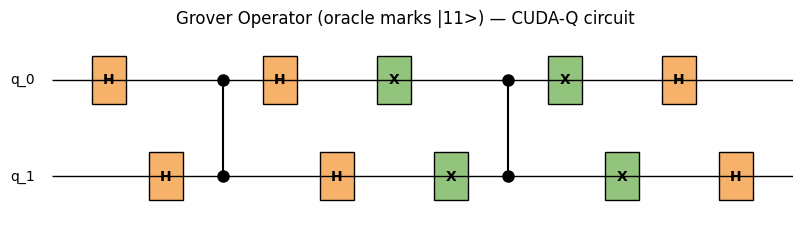

In [7]:
# Matplotlib circuit diagram, generated by looping over the shared GATES list
# above -- NOT hand-placed -- so it cannot silently drift from the kernel body.
fig, ax = plt.subplots(figsize=(10, 2.5))

for i in range(N_QUBITS):
    y = N_QUBITS - 1 - i
    ax.hlines(y, 0, len(GATES) + 1.5, color="black", linewidth=1)
    ax.text(-0.3, y, f"q_{i}", va="center", ha="right", fontsize=10)

for col, (gate_name, qubits, param) in enumerate(GATES):
    x_pos = col + 1
    if gate_name == "h":
        y = N_QUBITS - 1 - qubits[0]
        ax.add_patch(plt.Rectangle((x_pos - 0.3, y - 0.25), 0.6, 0.5,
                                    facecolor="#f6b26b", edgecolor="black"))
        ax.text(x_pos, y, "H", va="center", ha="center", fontsize=10, fontweight="bold")
    elif gate_name == "x":
        y = N_QUBITS - 1 - qubits[0]
        ax.add_patch(plt.Rectangle((x_pos - 0.3, y - 0.25), 0.6, 0.5,
                                    facecolor="#93c47d", edgecolor="black"))
        ax.text(x_pos, y, "X", va="center", ha="center", fontsize=10, fontweight="bold")
    elif gate_name == "cz":
        qa, qb = qubits
        y_a = N_QUBITS - 1 - qa
        y_b = N_QUBITS - 1 - qb
        ax.plot([x_pos, x_pos], [y_a, y_b], color="black", linewidth=1.5, zorder=1)
        ax.plot(x_pos, y_a, "o", color="black", markersize=8, zorder=2)
        ax.plot(x_pos, y_b, "o", color="black", markersize=8, zorder=2)
    else:
        raise ValueError(f"Unhandled gate in GATES for drawing: {gate_name}")

ax.set_xlim(-0.6, len(GATES) + 1)
ax.set_ylim(-0.5, N_QUBITS - 0.5)
ax.axis("off")
ax.set_title("Grover Operator (oracle marks |11>) — CUDA-Q circuit")

fig.savefig("grover_state_cudaq_circuit.png", bbox_inches="tight")
fig

## 4. Explicit matrix representation of the key operator(s)

In [8]:
H_matrix = (1 / np.sqrt(2)) * np.array([[1, 1],
                                          [1, -1]], dtype=complex)
X_matrix = np.array([[0, 1],
                      [1, 0]], dtype=complex)
print("H matrix:")
print(np.round(H_matrix, 4))
print()
print("X matrix:")
print(np.round(X_matrix, 4))
print()

def cz_matrix(qa, qb, n_qubits):
    """CZ matrix for arbitrary qubit pair in an n-qubit system, basis ordered
    with qubit 0 = rightmost (LSB) -- identical construction to the Qiskit notebook.
    CZ is symmetric in its two qubit arguments (order doesn't matter)."""
    dim = 2 ** n_qubits
    M = np.zeros((dim, dim), dtype=complex)
    for idx in range(dim):
        bits = [(idx >> k) & 1 for k in range(n_qubits)]
        phase = -1.0 if (bits[qa] == 1 and bits[qb] == 1) else 1.0
        M[idx, idx] = phase
    return M

def single_qubit_op_embedded(op, qubit, n_qubits):
    """Embed a 2x2 single-qubit operator into the full n-qubit space,
    with qubit 0 = rightmost/LSB."""
    mats = []
    for q in reversed(range(n_qubits)):
        mats.append(op if q == qubit else np.eye(2, dtype=complex))
    full = mats[0]
    for m in mats[1:]:
        full = np.kron(full, m)
    return full

CZ01 = cz_matrix(0, 1, N_QUBITS)
print(f"CZ(0, 1) matrix, {2**N_QUBITS}x{2**N_QUBITS}, basis qubit0=rightmost:")
print(np.round(CZ01.real, 4))

H matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

X matrix:
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

CZ(0, 1) matrix, 4x4, basis qubit0=rightmost:
[[ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0. -1.]]


In [9]:
# Build the full operator by multiplying the per-gate embedded matrices in
# GATES order (rightmost-applied-first matrix convention: first gate applied
# is the rightmost factor in the product).
H0 = single_qubit_op_embedded(H_matrix, 0, N_QUBITS)
H1 = single_qubit_op_embedded(H_matrix, 1, N_QUBITS)
X0 = single_qubit_op_embedded(X_matrix, 0, N_QUBITS)
X1 = single_qubit_op_embedded(X_matrix, 1, N_QUBITS)

GATE_MATRIX = {
    ("h", 0): H0, ("h", 1): H1,
    ("x", 0): X0, ("x", 1): X1,
    ("cz", (0, 1)): CZ01,
}

full_op = np.eye(2 ** N_QUBITS, dtype=complex)
for gate_name, qubits, param in GATES:
    if gate_name == "cz":
        M = GATE_MATRIX[("cz", tuple(qubits))]
    else:
        M = GATE_MATRIX[(gate_name, qubits[0])]
    full_op = M @ full_op   # newest gate applied on the left

print(f"Full {2**N_QUBITS}x{2**N_QUBITS} Grover operator (basis qubit0=rightmost), rounded:")
print(np.round(full_op, 4))

Full 4x4 Grover operator (basis qubit0=rightmost), rounded:
[[-0.+0.j -0.+0.j -0.+0.j  1.+0.j]
 [-0.+0.j -1.+0.j -0.+0.j  0.+0.j]
 [-0.+0.j -0.+0.j -1.+0.j  0.+0.j]
 [-1.+0.j -0.+0.j -0.+0.j  0.+0.j]]


## 5. Exact statevector, reordered (if needed) + global-phase normalized

In [10]:
state = cudaq.get_state(grover_kernel)
raw_amps = np.array(state)
print("Raw CUDA-Q amplitudes (native ordering):")
print(np.round(raw_amps, 4))

Raw CUDA-Q amplitudes (native ordering):
[ 0.+0.j  0.+0.j  0.+0.j -1.+0.j]


In [11]:
def reorder_if_needed(amps, n_qubits, needs_reversal):
    if not needs_reversal:
        return amps.copy()
    dim = 2 ** n_qubits
    reordered = np.zeros(dim, dtype=complex)
    for native_idx in range(dim):
        native_bits = format(native_idx, f"0{n_qubits}b")
        target_bits = native_bits[::-1]
        target_idx = int(target_bits, 2)
        reordered[target_idx] = amps[native_idx]
    return reordered

amps_contract = reorder_if_needed(raw_amps, N_QUBITS, NEEDS_REVERSAL)
print(f"Amplitudes after reordering (NEEDS_REVERSAL={NEEDS_REVERSAL}, matches CONTRACT):")
print(np.round(amps_contract, 4))

Amplitudes after reordering (NEEDS_REVERSAL=False, matches CONTRACT):
[ 0.+0.j  0.+0.j  0.+0.j -1.+0.j]


In [12]:
# Global phase normalization -- identical method to the Qiskit notebook.
def normalize_global_phase(statevector_data, n_qubits):
    dim = 2 ** n_qubits
    bitstrings = [format(i, f"0{n_qubits}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_norm, bitstrings = normalize_global_phase(amps_contract, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    exact_probs[bs] = round(abs(amps_norm[i]) ** 2, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector amplitudes (phase-normalized):")
print(np.round(amps_norm, 4))
print()
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector amplitudes (phase-normalized):
[0.-0.j 0.-0.j 0.-0.j 1.+0.j]

Exact statevector probabilities (qubit0 = rightmost):
{'00': np.float64(0.0), '01': np.float64(0.0), '10': np.float64(0.0), '11': np.float64(1.0)}


## 6. Measurement: sample, plot histogram

In [13]:
result = cudaq.sample(grover_kernel, shots_count=SHOTS)
raw_counts = {bs: result.count(bs) for bs in result}
print("Raw CUDA-Q counts (native bitstring ordering):")
print(raw_counts)

Raw CUDA-Q counts (native bitstring ordering):
{'11': 10000}


In [14]:
def reorder_counts_if_needed(counts, needs_reversal):
    if not needs_reversal:
        return dict(counts)
    out = {}
    for bs, c in counts.items():
        rbs = bs[::-1]
        out[rbs] = out.get(rbs, 0) + c
    return out

counts = reorder_counts_if_needed(raw_counts, NEEDS_REVERSAL)
sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in counts.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}), qubit0 = rightmost:")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42), qubit0 = rightmost:
{'11': 1.0}


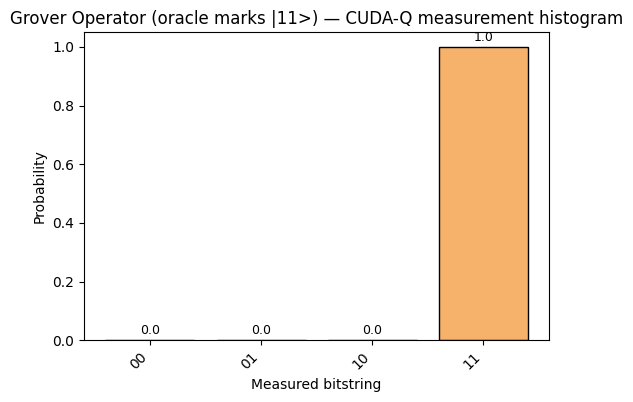

In [15]:
# Matplotlib bar chart styled like Qiskit's plot_histogram()
fig2, ax2 = plt.subplots(figsize=(6, 4))
all_bitstrings = [format(i, f"0{N_QUBITS}b") for i in range(2 ** N_QUBITS)]
labels = all_bitstrings
values = [sampled_probs.get(b, 0.0) for b in all_bitstrings]

ax2.bar(labels, values, color="#f6b26b", edgecolor="black")
ax2.set_xlabel("Measured bitstring")
ax2.set_ylabel("Probability")
ax2.set_title("Grover Operator (oracle marks |11>) — CUDA-Q measurement histogram")
ax2.set_ylim(0, 1.05)
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")
for i, v in enumerate(values):
    ax2.text(i, v + 0.02, str(v), ha="center", fontsize=9)

fig2.savefig("grover_state_cudaq_histogram.png", bbox_inches="tight")
fig2

## 7. Gate / operation count

In [16]:
gate_count = len(GATES)  # 4x H (prep) + 2x CZ + 4x X + 4x H (diffusion) = 12
print(f"Gate/operation count: {gate_count}")

Gate/operation count: 12


## 8. Convention notes

In [17]:
print(f"Bit ordering: calibration in Section 1 measured NEEDS_REVERSAL = {NEEDS_REVERSAL}")
print("(derived from an actual X-on-qubit-1 calibration kernel, not assumed from docs).")
print("Every downstream reversal -- statevector and sampled counts -- used that measured flag.")
print()
print("Global phase: computed and removed using the identical method as the Qiskit notebook --")
print("first nonzero amplitude in ascending-bitstring order is rotated to be real and positive.")
print("For this primitive, the ideal circuit leaves exactly one nonzero amplitude (|11>), so")
print("this normalization rotates that single amplitude to +1 regardless of its raw sign/phase.")

Bit ordering: calibration in Section 1 measured NEEDS_REVERSAL = False
(derived from an actual X-on-qubit-1 calibration kernel, not assumed from docs).
Every downstream reversal -- statevector and sampled counts -- used that measured flag.

Global phase: computed and removed using the identical method as the Qiskit notebook --
first nonzero amplitude in ascending-bitstring order is rotated to be real and positive.
For this primitive, the ideal circuit leaves exactly one nonzero amplitude (|11>), so
this normalization rotates that single amplitude to +1 regardless of its raw sign/phase.


## 9. Hand-derived expected result (independent sanity check)

Derived directly from the gate definitions, independent of the code above: with N = 4 basis states and M = 1 marked state (`|11>`), the optimal number of Grover iterations is `round((pi/4)*sqrt(N/M)) = 1`. Writing `theta = arcsin(sqrt(M/N)) = arcsin(1/2) = pi/6`, the success probability after k iterations is `sin^2((2k+1)*theta)`; for k = 1 that's `sin^2(3*pi/6) = sin^2(pi/2) = 1`. So a single iteration should leave the register in `|11>` with probability exactly 1.0, and every other bitstring at probability 0 -- this is one of the special cases where amplitude amplification is exact rather than approximate. Expected probabilities: `{'00': 0.0, '01': 0.0, '10': 0.0, '11': 1.0}`.

In [18]:
EXPECTED_PROBS = {format(i, f"0{N_QUBITS}b"): 0.0 for i in range(2 ** N_QUBITS)}
EXPECTED_PROBS["11"] = 1.0

max_delta_vs_hand = max(abs(exact_probs.get(k, 0) - EXPECTED_PROBS.get(k, 0))
                         for k in set(exact_probs) | set(EXPECTED_PROBS))
print("Max delta vs. hand-derived expectation:", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-6, "Computed result does not match hand-derived Grover-operator probabilities!"
print("Sanity check PASSED: exact_probs matches the hand-derived expectation.")

Max delta vs. hand-derived expectation: 0.0
Sanity check PASSED: exact_probs matches the hand-derived expectation.


## Final result (for diffing against QISKIT_RESULT)

In [19]:
CUDAQ_RESULT = exact_probs
print("CUDAQ_RESULT =", CUDAQ_RESULT)

CUDAQ_RESULT = {'00': np.float64(0.0), '01': np.float64(0.0), '10': np.float64(0.0), '11': np.float64(1.0)}
